# 2016 — Normalizing Flows (RealNVP)

**Papers:** Laurent Dinh, Jascha Sohl-Dickstein & Samy Bengio, *"Density estimation using Real NVP"* (2016, ICLR 2017). Earlier: Dinh, Krueger & Bengio, *NICE* (2014); Rezende & Mohamed, *"Variational Inference with Normalizing Flows"* (2015). Later: Kingma & Dhariwal, *Glow* (2018).

The other generative models in this repository give up something:
- A VAE (notebook 19) optimises a lower bound on the likelihood.
- A GAN (notebook 22) has no likelihood at all.

A **normalizing flow** computes the **exact** likelihood. Learn an invertible map $f$ from data $x$ to a simple base variable $z=f(x)\sim\mathcal N(0,I)$. The change-of-variables formula gives

$$\log p(x) = \log \mathcal N\big(f(x)\big) + \log\Big|\det \frac{\partial f}{\partial x}\Big|$$

The difficulty is building a flexible $f$ whose inverse and Jacobian determinant are cheap. RealNVP's **affine coupling layer** does it: split $x$ into halves $(x_a, x_b)$, keep $x_a$, and transform $x_b$ with a scale and shift computed from $x_a$:

$$y_a = x_a, \qquad y_b = x_b \odot e^{s(x_a)} + t(x_a)$$

The Jacobian is triangular, so $\log|\det| = \sum s(x_a)$. The inverse is $x_b = (y_b - t(y_a))\,e^{-s(y_a)}$. And $s, t$ can be any neural networks; they never need to be inverted. Stack layers, alternating which half is transformed.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)
from sklearn.datasets import make_moons
device = torch.device("cpu")      # 2-D toy data: CPU is fastest

PyTorch 2.15.0 | device: mps


In [2]:
X = torch.tensor(make_moons(4000, noise=0.05, random_state=0)[0], dtype=torch.float32)
X = (X - X.mean(0)) / X.std(0)

class Coupling(nn.Module):
    def __init__(self, mask, hidden=128):
        super().__init__(); self.register_buffer("mask", mask)
        self.net = nn.Sequential(nn.Linear(2, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 4))
    def st(self, x_keep):
        s, t = self.net(x_keep).chunk(2, -1)
        return torch.tanh(s) * (1 - self.mask), t * (1 - self.mask)            # only the transformed half gets s, t
    def forward(self, x):                                                     # data → latent
        s, t = self.st(x * self.mask)
        return x * self.mask + (1 - self.mask) * (x * torch.exp(s) + t), s.sum(-1)
    def inverse(self, y):                                                     # latent → data
        s, t = self.st(y * self.mask)
        return y * self.mask + (1 - self.mask) * ((y - t) * torch.exp(-s))

class RealNVP(nn.Module):
    def __init__(self, n_layers=8):
        super().__init__()
        masks = [torch.tensor([1.0, 0.0]) if i % 2 == 0 else torch.tensor([0.0, 1.0]) for i in range(n_layers)]
        self.layers = nn.ModuleList([Coupling(m) for m in masks])
        self.base = torch.distributions.MultivariateNormal(torch.zeros(2), torch.eye(2))
    def forward(self, x):
        logdet = torch.zeros(len(x))
        for l in self.layers: x, ld = l(x); logdet = logdet + ld
        return x, logdet
    def log_prob(self, x):
        z, logdet = self(x); return self.base.log_prob(z) + logdet
    def sample(self, n):
        z = self.base.sample((n,))
        for l in reversed(self.layers): z = l.inverse(z)
        return z

In [3]:
seed_everything(0)
flow = RealNVP(); opt = torch.optim.Adam(flow.parameters(), lr=1e-3); nll = []
for step in range(3000):
    x = X[torch.randint(0, len(X), (256,))]
    loss = -flow.log_prob(x).mean(); opt.zero_grad(); loss.backward(); opt.step(); nll.append(loss.item())
gauss = torch.distributions.MultivariateNormal(X.mean(0), torch.cov(X.T))
print(f"average negative log-likelihood (nats): RealNVP {-flow.log_prob(X).mean().item():.3f} | best single Gaussian {-gauss.log_prob(X).mean().item():.3f}")

average negative log-likelihood (nats): RealNVP 1.147 | best single Gaussian 2.726


## Checks: exact inverse, and the cheap log-determinant equals the true one

In [4]:
x = X[:5].clone().requires_grad_(True)
z, logdet = flow(x)
zz = z.detach()
for l in reversed(flow.layers): zz = l.inverse(zz)
print("max |f⁻¹(f(x)) − x| =", (zz - x.detach()).abs().max().item())
J = torch.stack([torch.autograd.functional.jacobian(lambda v: flow(v[None])[0][0], x[i].detach()) for i in range(5)])
print("log|det J| via autograd :", torch.linalg.slogdet(J)[1].numpy().round(4))
print("log|det J| via Σ s(x_a) :", logdet.detach().numpy().round(4))

max |f⁻¹(f(x)) − x| = 3.5762786865234375e-07
log|det J| via autograd : [1.7542 2.5434 2.8414 1.4555 2.4838]
log|det J| via Σ s(x_a) : [1.7542 2.5434 2.8414 1.4555 2.4838]


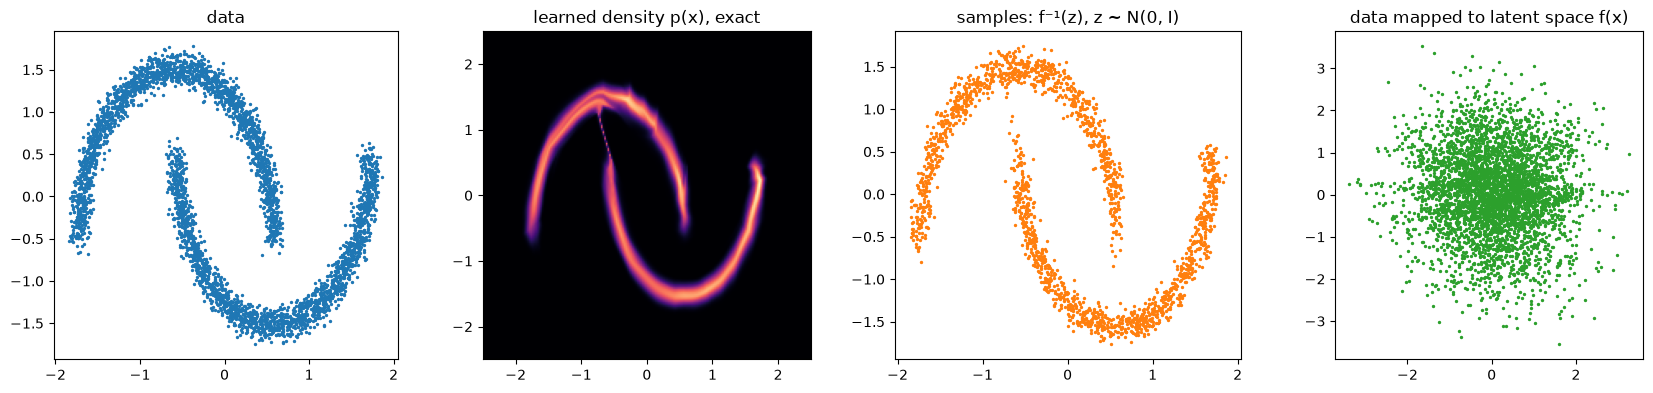

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
g = torch.linspace(-2.5, 2.5, 200); gx, gy = torch.meshgrid(g, g, indexing="xy")
with torch.no_grad():
    dens = flow.log_prob(torch.stack([gx.flatten(), gy.flatten()], 1)).exp().view(200, 200)
    s = flow.sample(2000); z, _ = flow(X)
axes[0].scatter(*X.T, s=2); axes[0].set_title("data")
axes[1].imshow(dens, extent=[-2.5, 2.5, -2.5, 2.5], origin="lower", cmap="magma"); axes[1].set_title("learned density p(x), exact")
axes[2].scatter(*s.T, s=2, c="C1"); axes[2].set_title("samples: f⁻¹(z), z ~ N(0, I)")
axes[3].scatter(*z.T, s=2, c="C2"); axes[3].set_title("data mapped to latent space f(x)")
for a in axes: a.set_aspect("equal")
plt.tight_layout(); plt.show()

## Takeaways
- **Exact likelihood and exact inverse** in one model: train by maximum likelihood, sample with one inverse pass, and encode data to latents with one forward pass.
- **The coupling trick** makes the Jacobian triangular, so its determinant is a sum. The networks inside ($s$, $t$) are unrestricted.
- **Limits:** every layer must keep the dimension, so flows are memory-hungry for images, and their sample quality on images trailed GANs and later diffusion. Glow (2018) generated faces; WaveGlow and Parallel WaveNet used flows for fast speech synthesis.
- **Legacy:** continuous-time flows (Neural ODEs, notebook 44) led directly to **flow matching** (notebook 55), which now trains the flows behind Stable Diffusion 3 and Flux, without the coupling-layer constraints.